# 02 – CT analysis

Analysis of the helical CT scan of phantom A3.

The notebook follows the structure of the project guide:

| Section | Content | Guide |
|---|---|---|
| 0 | Setup, data and acquisition parameters | – |
| 1 | Locating and cropping phantom A3 | – |
| 2 | Number, geometry and arrangement of objects | 1.1 |
| 3 | Internal structure and material characteristics | 1.2 |
| 4 | Contrast and image quality | 1.3 |
| 5 | Summary for the multimodal comparison | 1.4–1.5 |
| 6 | Reproducibility record | – |

Each analysis follows **question → method → result → interpretation/limitations**. Choices such as ROI positions, measurement lines and thresholds are made by the group in the viewer and written in the code cells marked *Placeholder*. Every choice is checked for how much it changes the result.

---
## 0. Setup and data

In [23]:
# === Autoreload: pick up changes in src/ automatically ===
%load_ext autoreload
%autoreload 2

# === Imports ===
import sys
sys.path.append("..")

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage.morphology import convex_hull_image

# === Our own functions ===
from src.data_io import load_series, save_table, save_figure
from src.viewers import viewer, plane_names, first_header, show_slice, contour_mm
from src.measure import roi_stats, roi_stability, line_profile, width_crossing, edge_width

# === Paths ===
RAW       = Path("../data/raw")
PROCESSED = Path("../data/processed")
RESULTS   = Path("../results")

CT_DIR     = RAW / "CT"
CT_HELICAL = CT_DIR / "Helical"      # Main dataset
CT_AXIAL_1 = CT_DIR / "Axial_1"      # Short axial scans (optional comparison)
CT_AXIAL_2 = CT_DIR / "Axial_2"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Load CT data and acquisition parameters

The helical CT series is loaded as a 3D volume in Hounsfield units, sorted by slice position. The slice spacing is calculated from the slice positions in the DICOM headers, not from `SliceThickness`. The acquisition parameters are collected for the Materials and methods section.

CT values are a calibrated physical quantity. The Hounsfield scale is defined from the linear attenuation coefficient $\mu$:

$$\mathrm{HU} = 1000 \cdot \frac{\mu - \mu_\mathrm{water}}{\mu_\mathrm{water}}$$

so water is 0 HU and air is about −1000 HU by definition, and cortical bone is typically 1000–2000 HU.

In [24]:
ct, ct_spacing = load_series(CT_HELICAL)
ct_names = plane_names(first_header(CT_HELICAL))
ds = first_header(CT_HELICAL)
dz, dy, dx = ct_spacing

print(f"Shape (slices, rows, cols): {ct.shape}")
print(f"Voxel spacing (mm): {tuple(round(s, 3) for s in ct_spacing)}")
print(f"Slice thickness in header: {ds.get('SliceThickness')} mm  |  slice spacing from positions: {dz:.3f} mm")
print(f"Planes: {ct_names}")

Shape (slices, rows, cols): (522, 512, 512)
Voxel spacing (mm): (0.625, 0.586, 0.586)
Slice thickness in header: 0.625000 mm  |  slice spacing from positions: 0.625 mm
Planes: ('Axial', 'Coronal', 'Sagittal')


In [25]:
# --- Acquisition parameters (for Materials and methods) ---
acq = pd.Series({
    "Manufacturer":            ds.get("Manufacturer"),
    "Model":                   ds.get("ManufacturerModelName"),
    "Tube voltage (kVp)":      ds.get("KVP"),
    "Tube current (mA)":       ds.get("XRayTubeCurrent"),
    "Exposure (mAs)":          ds.get("Exposure"),
    "Slice thickness (mm)":    ds.get("SliceThickness"),
    "Pixel spacing (mm)":      ds.get("PixelSpacing"),
    "Reconstruction kernel":   ds.get("ConvolutionKernel"),
    "CTDIvol (mGy)":           ds.get("CTDIvol"),
    "Patient position":        ds.get("PatientPosition"),
    "Image orientation":       ds.get("ImageOrientationPatient"),
}, name="CT Helical")

# --- Clipping: values piled up at the data maximum ---
# The header gives the storage range (BitsStored), but the scanner can limit the
# reconstructed values to a smaller range. A pile-up of many voxels at exactly the
# maximum value shows that values were clipped there.
bits     = int(ds.BitsStored)
data_max = float(ct.max())
n_at_max = int((ct == data_max).sum())

CLIP_HU = data_max
print(f"Bits stored: {bits} (storage range up to {2**bits - 1 + float(ds.RescaleIntercept):.0f} HU)")
print(f"Data maximum: {data_max:.0f} HU, reached by {n_at_max} voxels → clipping at {CLIP_HU:.0f} HU")

acq["Bits stored"] = bits
acq["Clipping value (HU)"] = CLIP_HU
acq.to_frame()

Bits stored: 16 (storage range up to 64511 HU)
Data maximum: 3071 HU, reached by 7557 voxels → clipping at 3071 HU


,CT Helical
Manufacturer,GE MEDICAL SYSTEMS
Model,Discovery MI
Tube voltage (kVp),100.0
Tube current (mA),300
Exposure (mAs),4
Slice thickness (mm),0.625
Pixel spacing (mm),"[0.585938, 0.585938]"
Reconstruction kernel,STANDARD
CTDIvol (mGy),None
Patient position,HFS


> **Missing parameters:** values shown as `None` can be found in the dose report (`CT/Dose_Report`) or the scan protocol.
>
> - ...

---
---
## 1. Locating phantom A3


In [45]:
viewer(ct, ct_spacing, names=ct_names, title="CT Helical - full volume", modality="CT")

### 1a. Finding the eight boxes

The CT contains eight phantoms (A1–A8), placed as four stacks of two boxes on the scanner table. Each box is found from its **water-like filling** (between `FILL_RANGE[0]` and `FILL_RANGE[1]` HU). The plastic walls have a lower HU than the filling, so each filling becomes its own connected region. The table (rows ≥ `TABLE_ROW`) is removed, thin connections are broken with a morphological opening, and holes left by objects are filled.

This step only locates the boxes. It does not identify any objects.

In [27]:
TABLE_ROW  = 340            # Rows from here down are the table (checked in the axial view)
FILL_RANGE = (-50, 300)     # HU range of the water-like filling
MIN_SIZE   = 100_000        # Minimum size of a box filling (voxels)

mask = (ct > FILL_RANGE[0]) & (ct < FILL_RANGE[1])
mask[:, TABLE_ROW:, :] = False                      # Remove the table
mask = ndimage.binary_opening(mask, iterations=2)   # Break thin connections
mask = ndimage.binary_fill_holes(mask)              # Fill holes left by objects

labels, n = ndimage.label(mask)
sizes = ndimage.sum(mask, labels, range(1, n + 1))
fills = [i + 1 for i, s in enumerate(sizes) if s > MIN_SIZE]
boxes = ndimage.find_objects(labels)

print(f"{n} regions found, {len(fills)} box fillings")

47 regions found, 8 box fillings


Saved figure: images/ct_detected_boxes.png


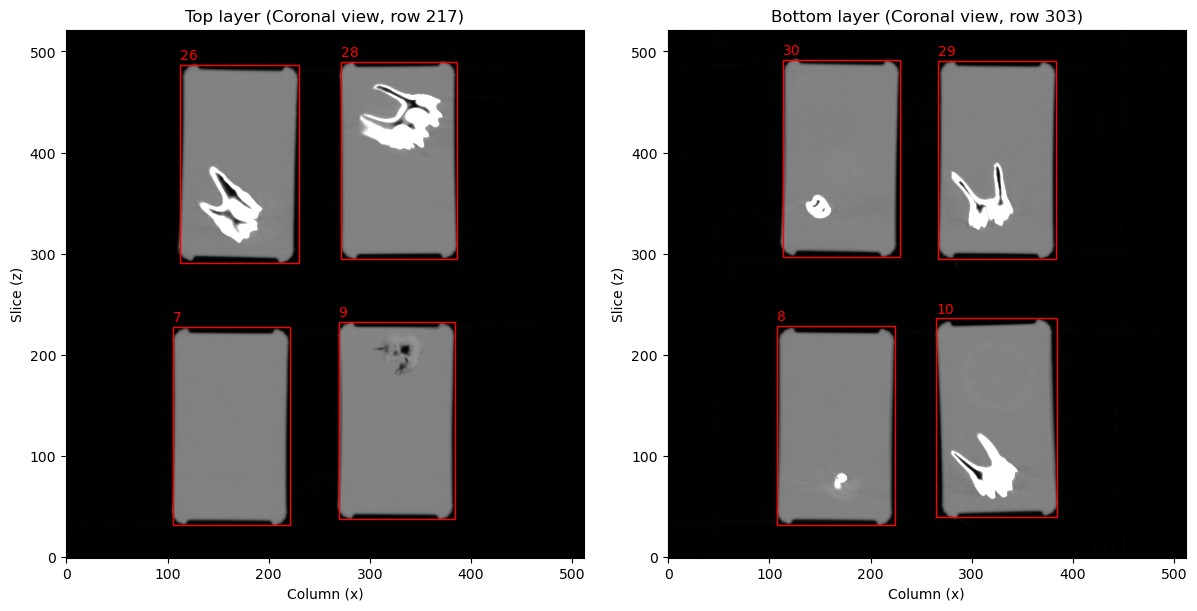

In [28]:
# --- Split the boxes into top and bottom layer by their vertical centre (y) ---
centers_y = {i: (boxes[i - 1][1].start + boxes[i - 1][1].stop) / 2 for i in fills}
y_split = np.median(list(centers_y.values()))      # Falls between the two layers (4 + 4 boxes)

layers = {
    "Top layer":    [i for i in fills if centers_y[i] < y_split],
    "Bottom layer": [i for i in fills if centers_y[i] >= y_split],
}

# --- Show both layers with the detected boxes ---
fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, (name, ids) in zip(axes, layers.items()):
    y_show = int(np.mean([centers_y[i] for i in ids]))       # Row through the middle of the layer
    ax.imshow(ct[:, y_show, :], cmap="gray", vmin=-1000, vmax=1000, origin="lower")
    for i in ids:
        sz, sy, sx = boxes[i - 1]
        ax.add_patch(plt.Rectangle((sx.start, sz.start), sx.stop - sx.start, sz.stop - sz.start,
                                   fill=False, edgecolor="r"))
        ax.text(sx.start, sz.stop + 5, str(i), color="r", fontsize=10)
    ax.set_title(f"{name} ({ct_names[1]} view, row {y_show})")
    ax.set_xlabel("Column (x)"); ax.set_ylabel("Slice (z)")
save_figure(fig, "ct_detected_boxes")
plt.show()

### 1b. Identifying box A3

Box A3 was identified from photos of the setup and the DICOM header:

- **Layer:** A3 is stacked on top of A1 → top layer (smaller row numbers in the axial images).
- **Position along the table:** A3/A1 is the stack closest to the gantry. The scan is head first (`PatientPosition` = HFS), so the gantry end corresponds to high slice numbers.
- **Side of the table:** the setup photo is taken from the left side of the bed, seen from the foot end, which is the patient's right in an HFS scan. With `ImageOrientationPatient` = [1, 0, 0, 0, 1, 0], the column index increases toward the patient's left, so A3 is at low column numbers.

The box is cropped from the bounding box of its filling plus a margin, so the plastic walls are included.

In [29]:
MARGIN = 10                                         # Voxels around the filling (~6 mm), includes the walls

# A3: top layer, highest z (gantry end), lowest x (patient's right)
a3_label = max(layers["Top layer"], key=lambda i: boxes[i - 1][0].start - boxes[i - 1][2].start)
sz, sy, sx = boxes[a3_label - 1]

Z_RANGE = (max(sz.start - MARGIN, 0), min(sz.stop + MARGIN, ct.shape[0]))
Y_RANGE = (max(sy.start - MARGIN, 0), min(sy.stop + MARGIN, ct.shape[1]))
X_RANGE = (max(sx.start - MARGIN, 0), min(sx.stop + MARGIN, ct.shape[2]))
crop = (slice(*Z_RANGE), slice(*Y_RANGE), slice(*X_RANGE))

ct_a3 = ct[crop]

print(f"A3 = label {a3_label}")
print(f"Crop: z {Z_RANGE}, y {Y_RANGE}, x {X_RANGE}")
print(f"Size (mm): {ct_a3.shape[0]*dz:.1f} x {ct_a3.shape[1]*dy:.1f} x {ct_a3.shape[2]*dx:.1f}")

A3 = label 26
Crop: z (281, 497), y (173, 262), x (102, 240)
Size (mm): 135.0 x 52.1 x 80.9


### 1c. Box interior and saving

The **box interior** is defined as the convex hull of the filling in each axial slice, shrunk by 2 voxels to avoid partial-volume voxels at the walls. The convex hull makes sure objects touching the walls are included. The interior is used for the segmentation below.

The crop is saved to `data/processed/ct_a3.npz` (volume, spacing, crop ranges and interior), so other notebooks can use it without loading the full CT.

In [30]:
filling = (labels == a3_label)[crop]

inside = np.zeros_like(filling)
for z in range(filling.shape[0]):
    if filling[z].any():                            # Skip slices outside the box
        inside[z] = convex_hull_image(filling[z])
inside = ndimage.binary_erosion(inside, iterations=2)

PROCESSED.mkdir(parents=True, exist_ok=True)
np.savez(PROCESSED / "ct_a3.npz", volume=ct_a3, spacing=np.array(ct_spacing),
         crop=np.array([Z_RANGE, Y_RANGE, X_RANGE]), inside=inside)
print("Saved: data/processed/ct_a3.npz")

Saved: data/processed/ct_a3.npz


---
---

## 2. Number, geometry and arrangement of objects  (Guide 1.1)

### 2a. Visual inspection

**Question:** How many distinct structures are in phantom A3, and where are they?

**Method:** Scroll through the phantom in all three planes. The *Soft tissue* window shows small HU differences, *Bone* shows dense structures and *Lung/air* shows air. Positions are read from the viewer as (slice, row, column) in the cropped volume and used as coordinates in the analyses below.

In [31]:
viewer(ct_a3, ct_spacing, names=ct_names, title="CT – phantom A3", modality="CT")

>**Observations:**
>
>| # | Structure    | Position (z, y, x) | Appearance | Notes |
>|---|--------------|--------------------|------------|-------|
>| 1 | Dense object | ... | ... | ... |
>| 2 | ... | ... | ... | ... |
>| 3 | ... | ... | ... | ... |
>| 4 | ... | ... | ... | ... |

### 2b. Threshold for the dense object

**Question:** Which HU threshold separates the dense object from the water-like filling?

**Method:** The HU distribution inside the box shows a narrow peak around 0 HU (the filling) and a broad tail up to the scanner's maximum `CLIP_HU` (the dense object). `DENSE_HU` is placed where the filling peak has dropped to the level of the tail. A threshold is an analytical choice, not an identification, so its effect on the volume is tested in 2d.

Saved figure: images/ct_a3_histogram.png


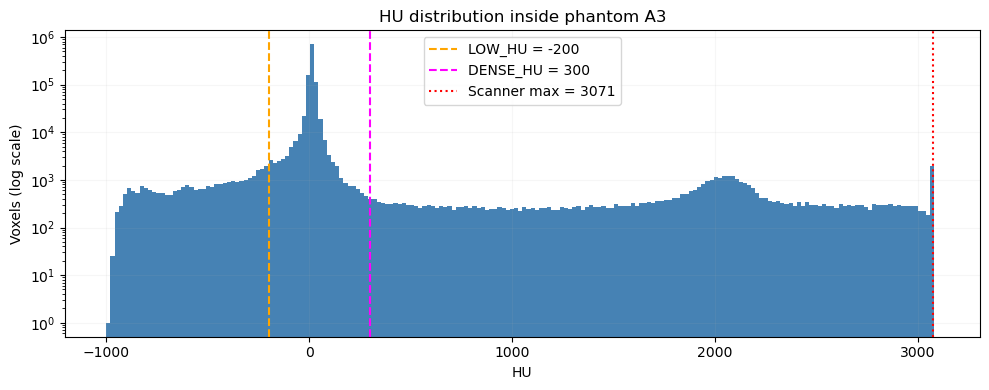

In [32]:
DENSE_HU = 300      # Threshold for the dense object (HU)
LOW_HU   = -200     # Threshold for air-like regions (HU)

fig = plt.figure(figsize=(10, 4))
plt.hist(ct_a3[inside], bins=200, range=(-1000, 3100), log=True, color="SteelBlue")
plt.axvline(LOW_HU,   c="orange",  ls="--", label=f"LOW_HU = {LOW_HU}")
plt.axvline(DENSE_HU, c="magenta", ls="--", label=f"DENSE_HU = {DENSE_HU}")
plt.axvline(CLIP_HU,  c="red",     ls=":",  label=f"Scanner max = {CLIP_HU:.0f}")
plt.xlabel("HU"); plt.ylabel("Voxels (log scale)")
plt.title("HU distribution inside phantom A3")
plt.legend(); plt.grid(alpha=0.1); plt.tight_layout()
save_figure(fig, "ct_a3_histogram")
plt.show()

### 2c. Segmentation of the dense object

**Question:** What is the shape and extent of the dense object?

**Method:** Voxels inside the box above `DENSE_HU` are segmented. Only the largest connected region is kept, and fully enclosed cavities are filled. The outline is drawn on the original image through the object's centre, to check that it follows the visible edge.

1 dense regions, largest sizes (voxels): [np.int64(52007)]
Dense object: 52037 voxels
Saved figure: images/ct_a3_object_outline.png


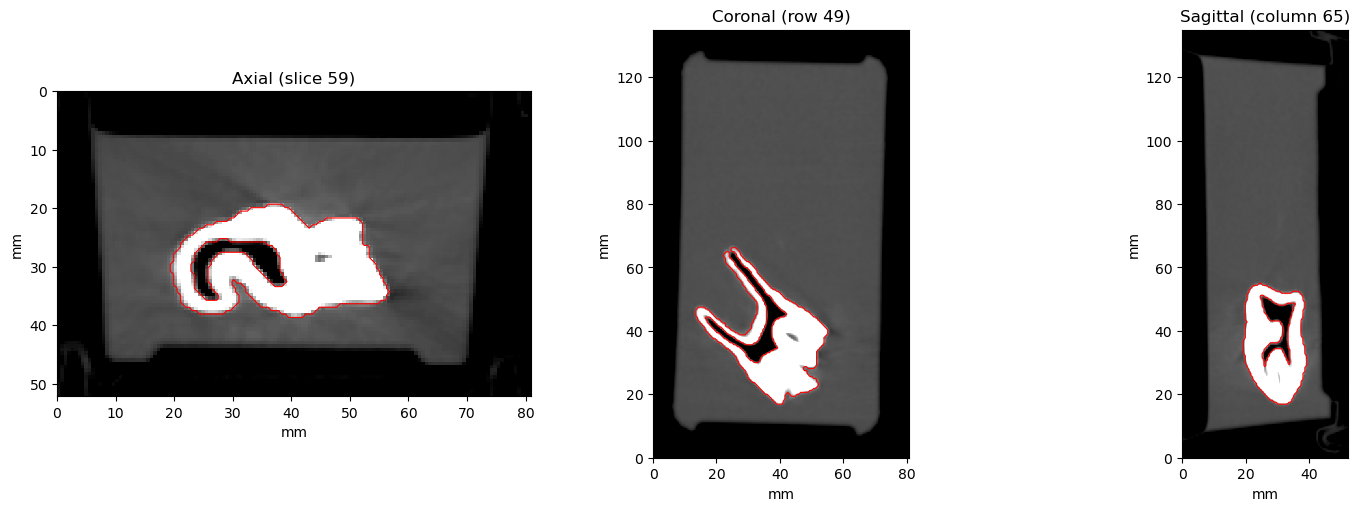

In [33]:
dense = inside & (ct_a3 > DENSE_HU)                                             # Dense voxels inside the box
dense_labels, n_dense = ndimage.label(dense)                                    # Connected regions
dense_sizes = np.bincount(dense_labels.ravel())[1:]                             # Size of each region (skip 0)
obj = ndimage.binary_fill_holes(dense_labels == (np.argmax(dense_sizes) + 1))   # Largest region, holes filled

print(f"{n_dense} dense regions, largest sizes (voxels): {sorted(dense_sizes, reverse=True)[:3]}")
print(f"Dense object: {obj.sum()} voxels")

# --- Check the outline on the original image (axes in mm) ---
cz, cy, cx = [int(c) for c in ndimage.center_of_mass(obj)]
views = [(ct_a3[cz],       obj[cz],       (dy, dx), "upper", f"{ct_names[0]} (slice {cz})"),
         (ct_a3[:, cy, :], obj[:, cy, :], (dz, dx), "lower", f"{ct_names[1]} (row {cy})"),
         (ct_a3[:, :, cx], obj[:, :, cx], (dz, dy), "lower", f"{ct_names[2]} (column {cx})")]

fig, ax = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for a, (img, m, sp, origin, title) in zip(ax, views):
    show_slice(a, img, sp, origin=origin, vmin=-450, vmax=1050)
    contour_mm(a, m, sp, colors="r", linewidths=0.8)
    a.set_title(title)
save_figure(fig, "ct_a3_object_outline")
plt.show()

### 2d. Volume of the dense object and threshold sensitivity

**Question:** How large is the dense object, and how much does the result depend on the threshold?

**Method:** Volume = number of voxels × voxel volume. The segmentation is repeated with `DENSE_HU` ± 100 HU, and the range is reported as an uncertainty. The bounding box is the extent along the image axes, so it is an upper limit for a tilted object; true dimensions are measured in 2e.

In [34]:
voxel_volume = dz * dy * dx                         # mm^3 per voxel

def segment_dense(threshold):
    lab, _ = ndimage.label(inside & (ct_a3 > threshold))
    s = np.bincount(lab.ravel())[1:]
    return ndimage.binary_fill_holes(lab == (np.argmax(s) + 1))

vols = {t: segment_dense(t).sum() * voxel_volume for t in [DENSE_HU - 100, DENSE_HU, DENSE_HU + 100]}

bz, by, bx = ndimage.find_objects(obj.astype(int))[0]
com = ndimage.center_of_mass(obj)

geometry = pd.Series({
    "Volume (mm^3)":       round(vols[DENSE_HU]),
    "Volume range (mm^3)": f"{min(vols.values()):.0f}–{max(vols.values()):.0f}",
    "Extent z (mm)":       round((bz.stop - bz.start) * dz, 1),
    "Extent y (mm)":       round((by.stop - by.start) * dy, 1),
    "Extent x (mm)":       round((bx.stop - bx.start) * dx, 1),
    "Centre (z, y, x) mm": tuple(round(c * s, 1) for c, s in zip(com, ct_spacing)),
}, name="Dense object")

print("Volume vs threshold (mm^3):", {k: round(v) for k, v in vols.items()})
geometry.to_frame()

Volume vs threshold (mm^3): {200: 11793, 300: 11166, 400: 10807}


,Dense object
Volume (mm^3),11166
Volume range (mm^3),10807–11793
Extent z (mm),50.0
Extent y (mm),19.9
Extent x (mm),43.9
"Centre (z, y, x) mm","(37.3, 29.3, 38.2)"


### 2e. Manual dimension measurements

**Question:** What are the true dimensions of the structures, measured along their own axes?

**Method:** Line profiles are drawn between two points chosen in the viewer (slice, row, column). Each line should extend a few mm into the filling on both sides. The size is the width where the profile passes the half-way level between the filling and the structure (similar to a full width at half maximum): above it for dense structures, below it for air.

Each line is drawn on the axial slice through its midpoint, so the measurement position can be checked. Lines that are tilted in z are only approximately shown.

Saved figure: images/ct_a3_dimension_profiles.png


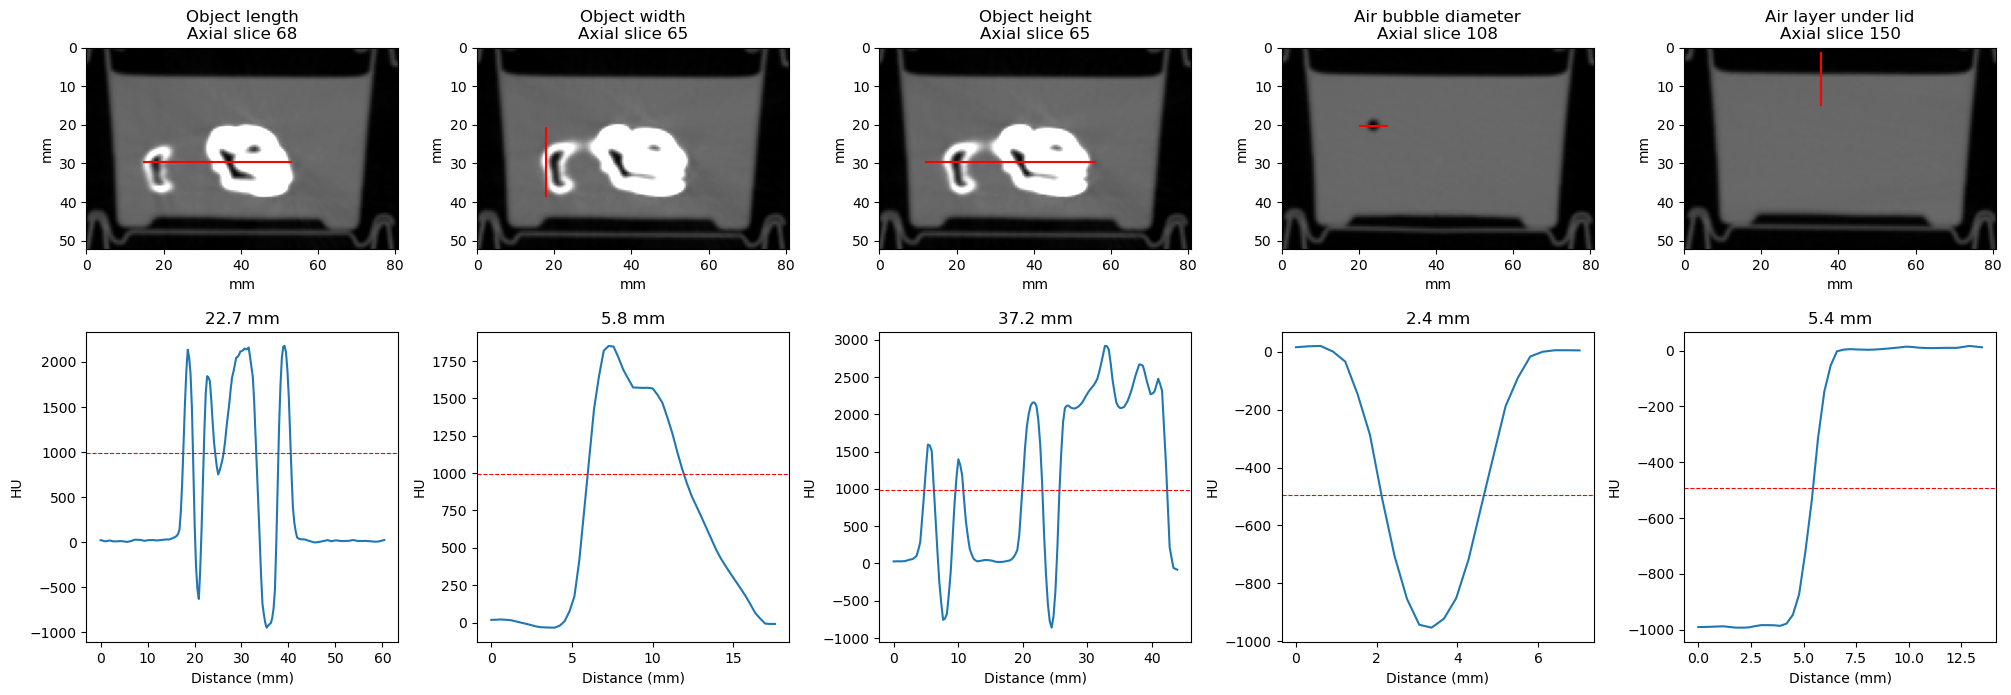

,Size (mm),Uncertainty (± mm)
Measurement,,
Object length,22.7,0.6
Object width,5.8,0.6
Object height,37.2,0.6
Air bubble diameter,2.4,0.6
Air layer under lid,5.4,0.6


In [35]:
# Placeholder: start and end points in voxels (z, y, x) of the cropped volume
# "kind": "dense" for the dense object, "air" for air bubbles or air layers
MEASURE_LINES = {
    "Object length":          {"p0": (30, 50, 25),  "p1": (105, 50, 90), "kind": "dense"},
    "Object width":           {"p0": (65, 35, 30),  "p1": (65, 65, 30),  "kind": "dense"},
    "Object height":          {"p0": (65, 50, 20),  "p1": (65, 50, 95),  "kind": "dense"},
    "Air bubble diameter":    {"p0": (108, 34, 34), "p1": (108, 34, 46), "kind": "air"},
    "Air layer under lid":    {"p0": (150, 2, 60),  "p1": (150, 25, 60), "kind": "air"},
}

fill_level = float(np.median(ct_a3[inside & ~obj]))        # Typical filling value
obj_level  = float(np.median(ct_a3[obj]))                  # Typical object value
air_level  = -1000.0                                       # Air by definition
levels = {"dense": (fill_level + obj_level) / 2, "air": (fill_level + air_level) / 2}

n_lines = len(MEASURE_LINES)
fig, ax = plt.subplots(2, n_lines, figsize=(4 * n_lines, 7), constrained_layout=True)
rows = []
for k, (name, L) in enumerate(MEASURE_LINES.items()):
    dist, vals = line_profile(ct_a3, ct_spacing, L["p0"], L["p1"])
    level = levels[L["kind"]]
    w = width_crossing(dist, vals, level, above=(L["kind"] == "dense"))
    rows.append({"Measurement": name, "Size (mm)": round(w, 1),
                 "Uncertainty (± mm)": round(max(ct_spacing), 1)})   # ~1 voxel

    # Top: line on the axial slice through its midpoint
    zm = int(round((L["p0"][0] + L["p1"][0]) / 2))
    show_slice(ax[0, k], ct_a3[zm], (dy, dx), vmin=-1000, vmax=1500)
    ax[0, k].plot([(L["p0"][2] + 0.5) * dx, (L["p1"][2] + 0.5) * dx],
                  [(L["p0"][1] + 0.5) * dy, (L["p1"][1] + 0.5) * dy], c="r")
    ax[0, k].set_title(f"{name}\n{ct_names[0]} slice {zm}")

    # Bottom: profile with the level used
    ax[1, k].plot(dist, vals)
    ax[1, k].axhline(level, c="r", ls="--", lw=0.8)
    ax[1, k].set_title(f"{w:.1f} mm"); ax[1, k].set_xlabel("Distance (mm)"); ax[1, k].set_ylabel("HU")
save_figure(fig, "ct_a3_dimension_profiles")
plt.show()

manual_dims = pd.DataFrame(rows).set_index("Measurement")
manual_dims

>**Results and interpretation:**
> - Number of objects, shape, dimensions, position in the box (e.g. lying on the bottom, near one end), orientation:
> - Do the manual dimensions agree with the bounding box in 2d? If not, why (tilt, irregular shape)?
>
>**Uncertainty:**
> - Threshold choice (volume range in 2d), endpoint choice (repeat a line a few voxels away), voxel size (±1 voxel), partial volume at small structures (e.g. the air bubble).

---
---
## 3. Internal structure and material characteristics  (Guide 1.2)

### 3a. Air-filled cavities in the dense object

**Question:** Does the dense object contain cavities, and what are they filled with?

**Method:** Cavities are voxels below `LOW_HU` inside the box. A seed point inside each cavity is chosen in the viewer, and the connected low-density region containing that seed is taken as the cavity. This avoids depending on label numbers, which change when thresholds change. The result is drawn on the original image (cyan) together with the dense object (red).

In [36]:
# Helper: low-density regions touching the dense object, with a point inside each
low_labels, _ = ndimage.label(inside & (ct_a3 < LOW_HU))
near_obj = ndimage.binary_dilation(obj, iterations=2)

for lab in np.unique(low_labels[near_obj]):
    if lab == 0:
        continue
    region = low_labels == lab
    pts = np.argwhere(region)
    seed = tuple(int(v) for v in pts[len(pts) // 2])        # A voxel inside the region
    print(f"Region {lab}: {region.sum()} voxels, example point (z, y, x) = {seed}")

Region 8: 4498 voxels, example point (z, y, x) = (67, 53, 31)
Region 9: 4 voxels, example point (z, y, x) = (60, 59, 98)
Region 10: 1 voxels, example point (z, y, x) = (67, 44, 75)
Region 11: 1 voxels, example point (z, y, x) = (68, 58, 31)


In [37]:
# Placeholder: one point (z, y, x) inside each cavity, chosen in the viewer
CAVITY_SEEDS = [(70, 50, 45)]

low_labels, _ = ndimage.label(inside & (ct_a3 < LOW_HU))

def region_at(seed, search=2):
    # Low-density region at (or within `search` voxels of) a seed point
    sl = tuple(slice(max(c - search, 0), c + search + 1) for c in seed)
    found = low_labels[sl][low_labels[sl] > 0]
    if found.size == 0:
        print(f"No low-density region near {seed}, check the seed in the viewer")
        return np.zeros_like(low_labels, dtype=bool)
    return low_labels == np.bincount(found).argmax()

cavities = np.zeros_like(inside)
for seed in CAVITY_SEEDS:
    cavities |= region_at(seed)

print(f"Cavities: {cavities.sum()} voxels = {cavities.sum() * voxel_volume:.0f} mm^3")

# --- Check on the original image ---
if cavities.any():
    ccx = int(ndimage.center_of_mass(cavities)[2])
    fig, ax = plt.subplots(figsize=(5, 6))
    show_slice(ax, ct_a3[:, :, ccx], (dz, dy), origin="lower", vmin=-1000, vmax=1500)
    contour_mm(ax, cavities[:, :, ccx], (dz, dy), colors="cyan", linewidths=0.8)
    contour_mm(ax, obj[:, :, ccx], (dz, dy), colors="r", linewidths=0.8)
    ax.set_title(f"Cavities (cyan) and object (red), {ct_names[2]} column {ccx}")
    plt.show()

No low-density region near (70, 50, 45), check the seed in the viewer
Cavities: 0 voxels = 0 mm^3


### 3b. HU in the core of the dense object

**Question:** How dense is the object material, and is it homogeneous?

**Method:** Voxels at the edge of the object are mixed with the filling (partial volume), which lowers their HU. The object is therefore also measured in its **core**: the segmentation shrunk by `CORE_EROSION` voxels. The share of clipped voxels shows how much of the object is above the scanner's maximum value. Clipped voxels make the mean a lower limit; the median is less affected.

In [38]:
CORE_EROSION = 3    # Voxels removed from the object surface

core = ndimage.binary_erosion(obj & ~cavities, iterations=CORE_EROSION)

def hu_stats(values, name):
    if values.size == 0:
        return {"Region": name, "Voxels": 0}
    return {"Region": name,
            "Voxels": values.size,
            "Mean HU": round(float(values.mean()), 0),
            "Median HU": round(float(np.median(values)), 0),
            "Std HU": round(float(values.std(ddof=1)), 0),
            "Clipped (%)": round(100 * (values >= CLIP_HU).mean(), 1)}

material = pd.DataFrame([hu_stats(ct_a3[obj],      "Whole object"),
                         hu_stats(ct_a3[core],     "Object core"),
                         hu_stats(ct_a3[cavities], "Cavities")]).set_index("Region")
material

,Voxels,Mean HU,Median HU,Std HU,Clipped (%)
Region,,,,,
Whole object,52037,1814.0,1969.0,746.0,3.5
Object core,18993,2277.0,2183.0,425.0,4.0
Cavities,0,NaN,NaN,NaN,NaN


### 3c. Profile through the internal structure

**Question:** How does the HU change across the object and its cavities?

**Method:** One line through the object **and** a cavity, so the profile shows filling → object → cavity → object → filling. Choose the points in the viewer.

Saved figure: images/ct_a3_internal_profile.png


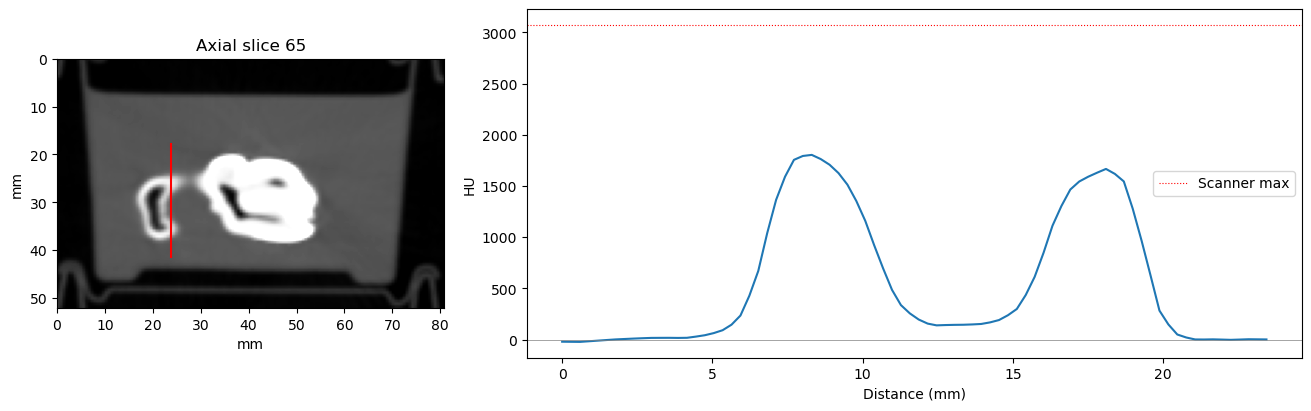

In [39]:
P0, P1 = (65, 30, 40), (65, 70, 40)     # Placeholder: start and end point (z, y, x)

dist, vals = line_profile(ct_a3, ct_spacing, P0, P1)
z0 = int(round((P0[0] + P1[0]) / 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True, width_ratios=[1, 2])
show_slice(ax[0], ct_a3[z0], (dy, dx), vmin=-1000, vmax=2000)
ax[0].plot([(P0[2] + 0.5) * dx, (P1[2] + 0.5) * dx], [(P0[1] + 0.5) * dy, (P1[1] + 0.5) * dy], c="r")
ax[0].set_title(f"{ct_names[0]} slice {z0}")
ax[1].plot(dist, vals)
ax[1].axhline(0, c="gray", lw=0.5)
ax[1].axhline(CLIP_HU, c="r", ls=":", lw=0.8, label="Scanner max")
ax[1].set_xlabel("Distance (mm)"); ax[1].set_ylabel("HU"); ax[1].legend()
save_figure(fig, "ct_a3_internal_profile")
plt.show()

>**Results and interpretation (observations, not identification yet):**
> - Is the object homogeneous, or are there layers / regions with different HU?
> - Cavities: size, shape, open or closed, filled with air (≈ −1000 HU) or something else?
> - What does the HU range say about density and composition? Higher $\mu$ means higher density and/or effective atomic number. Compare with water (0 HU), air (−1000 HU) and cortical bone (1000–2000 HU).
>
>**Limitations:** clipping, partial volume at thin parts and cavity edges.

---
---
## 4. Contrast and image quality  (Guide 1.3)

### 4a. ROI measurements and their stability

**Question:** How well are the structures distinguished from the filling, and how robust are the ROI values?

**Method:** ROIs are placed in the viewer, fully inside each structure and away from edges. For each ROI, `roi_stability` moves it ±2 voxels in every direction and changes its size by ±1 voxel; the range of the mean shows how sensitive the result is to the ROI choice.

ROIs placed in the core of the dense object will contain clipped voxels, so their mean is a lower limit. Small structures (like the air bubble) only allow tiny ROIs, so their values are affected by partial volume.

,Mean HU,Median HU,Std in ROI (HU),Voxels,Mean range when moved (HU)
ROI,,,,,
Filling (far from object),16.8,17.0,5.6,1331,16 to 18
Filling (near object),8.8,14.0,32.5,1331,-1 to 51
Object core,52.1,36.0,48.6,27,9 to 1408
Air bubble,-772.6,-821.0,154.0,27,-958 to -27
Air under lid,-985.9,-986.0,5.8,165,-994 to -829


Saved figure: images/ct_a3_rois.png


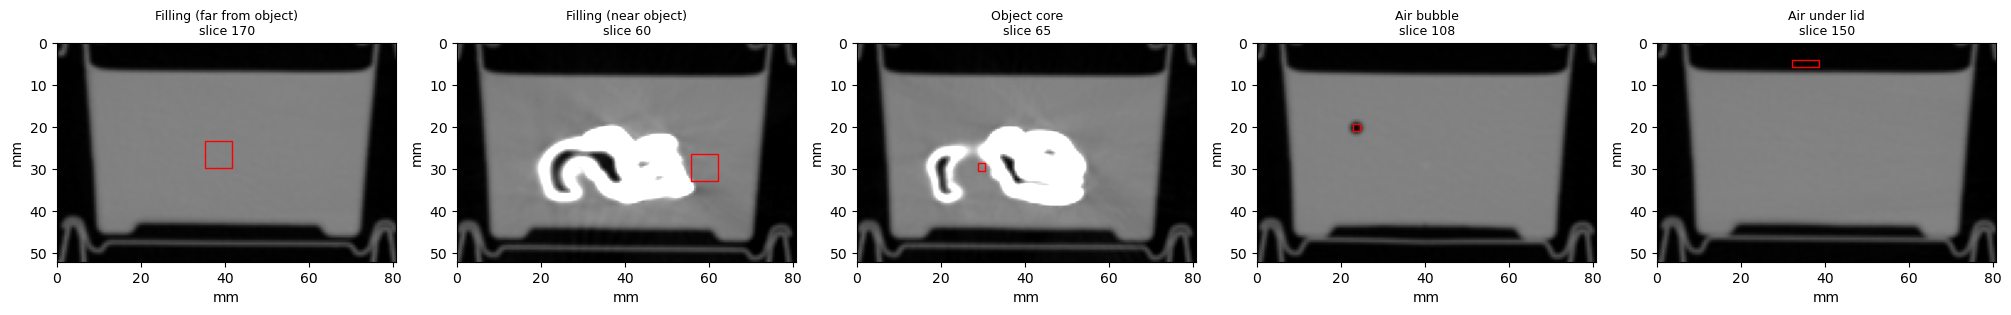

In [40]:
# Placeholder: ROI centre (z, y, x) and half-size (z, y, x) in voxels of the cropped volume
ROIS = {
    "Filling (far from object)":  {"center": (170, 45, 65), "half": (5, 5, 5)},
    "Filling (near object)":      {"center": (60, 50, 100), "half": (5, 5, 5)},
    "Object core":                {"center": (65, 50, 50),  "half": (1, 1, 1)},
    "Air bubble":                 {"center": (108, 34, 40), "half": (1, 1, 1)},
    "Air under lid":              {"center": (150, 8, 60),  "half": (2, 1, 5)},
}

roi_rows = []
for name, r in ROIS.items():
    s = roi_stats(ct_a3, r["center"], r["half"])
    lo, hi = roi_stability(ct_a3, r["center"], r["half"])
    roi_rows.append({"ROI": name, "Mean HU": round(s["mean"], 1), "Median HU": round(s["median"], 1),
                     "Std in ROI (HU)": round(s["std"], 1), "Voxels": s["n"],
                     "Mean range when moved (HU)": f"{lo:.0f} to {hi:.0f}"})
roi_table = pd.DataFrame(roi_rows).set_index("ROI")
display(roi_table)

# --- Draw each ROI on its axial slice (axes in mm) ---
fig, ax = plt.subplots(1, len(ROIS), figsize=(4 * len(ROIS), 3.5), constrained_layout=True)
for a, (name, r) in zip(ax, ROIS.items()):
    (cz_, cy_, cx_), (hz, hy, hx) = r["center"], r["half"]
    show_slice(a, ct_a3[cz_], (dy, dx), vmin=-1000, vmax=1000)
    a.add_patch(plt.Rectangle(((cx_ - hx) * dx, (cy_ - hy) * dy), (2 * hx + 1) * dx, (2 * hy + 1) * dy,
                              fill=False, edgecolor="r"))
    a.set_title(f"{name}\nslice {cz_}", fontsize=9)
save_figure(fig, "ct_a3_rois")
plt.show()

### 4b. Noise estimate, contrast and CNR

**Question:** Is the standard deviation in the filling a valid noise estimate, and what is the CNR of each structure?

**Method:** The within-ROI standard deviation includes all variation in the ROI, not only random noise. It is only used as the noise $\sigma_N$ if the filling is homogeneous, which is checked by comparing two filling ROIs: one far from the object and one near it. If the near ROI has a clearly higher standard deviation, the object causes artefacts (e.g. streaks), and the far ROI is used for $\sigma_N$.

Contrast and contrast-to-noise ratio between structure A and the filling B:

$$C_{AB} = |S_A - S_B|, \qquad \mathrm{CNR}_{AB} = \frac{|S_A - S_B|}{\sigma_N}$$

In [41]:
sd_far  = roi_table.loc["Filling (far from object)", "Std in ROI (HU)"]
sd_near = roi_table.loc["Filling (near object)", "Std in ROI (HU)"]
print(f"Std in filling: far {sd_far:.1f} HU, near object {sd_near:.1f} HU")

sigma_N = sd_far
S_fill  = roi_table.loc["Filling (far from object)", "Mean HU"]

contrast = pd.DataFrame([
    {"Structure": name,
     "Contrast C (HU)": round(abs(roi_table.loc[name, "Mean HU"] - S_fill), 0),
     "CNR": round(abs(roi_table.loc[name, "Mean HU"] - S_fill) / sigma_N, 1)}
    for name in ["Object core", "Air bubble", "Air under lid"]
]).set_index("Structure")

print(f"Noise σ_N = {sigma_N:.1f} HU (filling far from the object)")
contrast

Std in filling: far 5.6 HU, near object 32.5 HU
Noise σ_N = 5.6 HU (filling far from the object)


,Contrast C (HU),CNR
Structure,,
Object core,35.0,6.3
Air bubble,789.0,141.0
Air under lid,1003.0,179.1


>**Interpretation:**
> - Is the filling homogeneous (similar std far and near the object)? Is $\sigma_N$ justified?
> - How do the CNR values compare between the structures? Which structures are easy or hard to see, and why?
> - How sensitive are the ROI means to the ROI position (range column)?

### 4c. Edge sharpness (spatial resolution)

**Question:** How sharp are boundaries in the image compared with the voxel size?

**Method:** The 10–90 % edge width of a profile across one sharp boundary is a simple measure of spatial resolution. Choose a short line (10–15 mm) that crosses one edge at right angles, e.g. from the filling into the dense object. Measuring the same edge in-plane and along z shows the difference between pixel spacing and slice spacing.

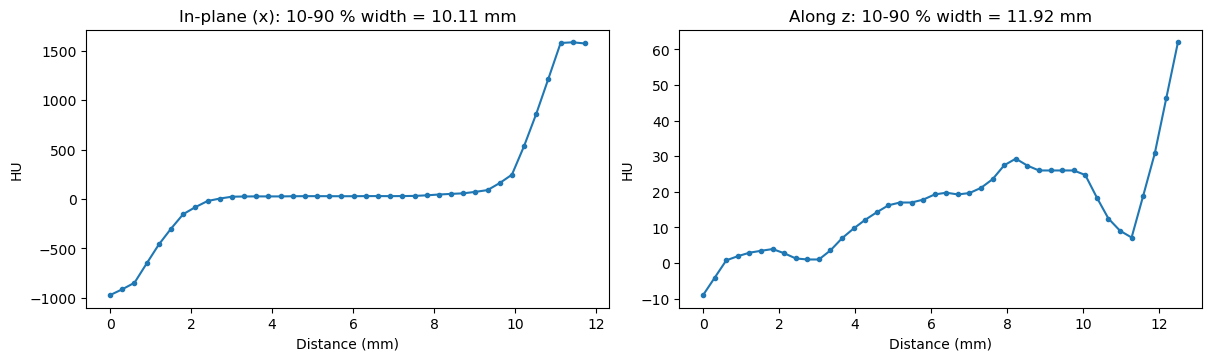

Pixel spacing: 0.586 mm  |  slice spacing: 0.625 mm


In [42]:
# Placeholder: lines (z, y, x) crossing one edge each
EDGES = {
    "In-plane (x)": ((65, 50, 10), (65, 50, 30)),
    "Along z":      ((20, 50, 50), (40, 50, 50)),
}

fig, ax = plt.subplots(1, len(EDGES), figsize=(6 * len(EDGES), 3.5), constrained_layout=True)
for a, (name, (e0, e1)) in zip(np.atleast_1d(ax), EDGES.items()):
    dist, vals = line_profile(ct_a3, ct_spacing, e0, e1)
    ew = edge_width(dist, vals)
    a.plot(dist, vals, marker=".")
    a.set_xlabel("Distance (mm)"); a.set_ylabel("HU")
    a.set_title(f"{name}: 10-90 % width = {ew:.2f} mm")
plt.show()

print(f"Pixel spacing: {dy:.3f} mm  |  slice spacing: {dz:.3f} mm")

### 4d. Artefacts

**Question:** Which artefacts are present, and how do they affect the measurements?

**Method:** Inspect the phantom in the viewer with a narrow window (e.g. *Soft tissue*) and compare with the ROI results above.

>**Observations:**
> - **Clipping:** voxels at `CLIP_HU` → the true HU of the dense object is underestimated.
> - **Streaks / beam hardening** next to the dense object: visible? Effect on the "near object" ROI?
> - **Partial volume:** edges, thin structures, the small air bubble.
> - Other: ...

---
---
## 5. Summary for the multimodal comparison  (Guide 1.4–1.5)

Only observations and measurements go here. What the objects are is decided in `06_comparison.ipynb`, together with MRI, X-ray and ultrasound.

>**CT evidence per structure:**
>
>| Structure | Visible in CT? | Size / volume (± uncertainty) | HU (median, range) | Internal structure | Limitations |
>|---|---|---|---|---|---|
>| Dense object | | | | | |
>| Cavities in object | | | | | |
>| Air bubble | | | | | |
>| Air layer under lid | | | | | |
>| Filling | | | | | |
>
>**What CT shows well:** ...
>
>**What CT cannot show / limitations:** ...

The key numbers are saved for notebook 06, so the comparison uses the same values as this notebook.

In [43]:
key_numbers = pd.concat([
    geometry.rename(lambda k: f"Dense object - {k}"),
    manual_dims["Size (mm)"].rename(lambda k: f"{k} (mm)"),
    material["Median HU"].rename(lambda k: f"{k} - median HU"),
    material["Clipped (%)"].rename(lambda k: f"{k} - clipped (%)"),
    roi_table["Mean HU"].rename(lambda k: f"ROI {k} - mean HU"),
    contrast["CNR"].rename(lambda k: f"CNR {k}"),
    pd.Series({"Noise sigma_N (HU)": sigma_N, "Cavities volume (mm^3)": round(cavities.sum() * voxel_volume)}),
])
key_numbers = key_numbers.rename("CT").to_frame()
display(key_numbers)
save_table(key_numbers.reset_index(names="Quantity"), "ct_key_numbers")

,CT
Dense object - Volume (mm^3),11166
Dense object - Volume range (mm^3),10807–11793
Dense object - Extent z (mm),50.0
Dense object - Extent y (mm),19.9
Dense object - Extent x (mm),43.9
"Dense object - Centre (z, y, x) mm","(37.3, 29.3, 38.2)"
Object length (mm),22.7
Object width (mm),5.8
Object height (mm),37.2
Air bubble diameter (mm),2.4


Saved table: results/ct_key_numbers.csv


---
---
## 6. Reproducibility record

All choices made in this notebook (crop, thresholds, ROI positions, measurement lines and seeds) are saved to `results/ct_settings.json`, so another group can repeat every measurement exactly.

In [44]:
settings = {
    "dataset": str(CT_HELICAL),
    "spacing_mm (dz, dy, dx)": [round(s, 4) for s in ct_spacing],
    "crop (z, y, x)": [list(Z_RANGE), list(Y_RANGE), list(X_RANGE)],
    "FILL_RANGE": list(FILL_RANGE), "TABLE_ROW": TABLE_ROW,
    "DENSE_HU": DENSE_HU, "LOW_HU": LOW_HU, "CLIP_HU": CLIP_HU,
    "CORE_EROSION": CORE_EROSION,
    "CAVITY_SEEDS": [list(s) for s in CAVITY_SEEDS],
    "MEASURE_LINES": {k: {"p0": list(v["p0"]), "p1": list(v["p1"]), "kind": v["kind"]}
                      for k, v in MEASURE_LINES.items()},
    "PROFILE (P0, P1)": [list(P0), list(P1)],
    "EDGES": {k: [list(a), list(b)] for k, (a, b) in EDGES.items()},
    "ROIS": {k: {"center": list(v["center"]), "half": list(v["half"])} for k, v in ROIS.items()},
}

RESULTS.mkdir(parents=True, exist_ok=True)
with open(RESULTS / "ct_settings.json", "w") as f:
    json.dump(settings, f, indent=2, default=float)
print("Saved: results/ct_settings.json")

Saved: results/ct_settings.json
